# Fold summary for the 300 m hurdle model cells

Per fold counts for the folds `hurdle_model_train.py` can draw over `data/cells_2019_2024_300m`: the default 5 fold blocked CV, and the two halves of Florida from `FOLD_SCHEME = "north_south"` or `"east_west"`. Cells and checks come from `hurdle_model_train.load_checked_cells`, with the script's `CELL_DIR` overridden here since it may point at a different cell size. Folds come from `hurdle_model_train.assign_scheme_folds`, the same function the script calls, so the table matches whatever the script would train on for that scheme.

Each row is one fold's held out cells. Training for fold k is every other row put together.

Two rates per fold:

* **pixel conversion rate**: 2019 wetland pixels developed by 2024 over all 2019 wetland pixels in the fold, `sum(n_developed) / sum(n_wetland)`. This is the pixel level positive rate.
* **any conversion rate**: share of cells with at least one developed pixel, `n_developed > 0`. This is the stage one classifier's positive rate, which its AUPRC should be read against.

Every cell is counted, the same as the val split. `MIN_WETLAND_TRAIN` only drops cells from train.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from pyproj import Transformer

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
# hurdle_model_train opens data/ by relative path, so run from the repo root.
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import arrays as array_io
import folds
import hurdle_model_train as hmt
from population_stats import load_population_stats

hmt.CELL_DIR = "data/cells_2019_2024_300m"
cells, cell_manifest, _, provenance = hmt.load_checked_cells()
population_stats = load_population_stats(hmt.POPULATION_STATS_PATH)

n_wet = cells["n_wetland"].astype(np.int64)
n_dev = cells["n_developed"].astype(np.int64)
FMT = {
    "n_blocks": "{:,}", "n_cells": "{:,}", "n_cells_any_conversion": "{:,}",
    "wetland_px": "{:,}", "developed_px": "{:,}", "share_of_cells": "{:.1%}",
    "share_of_wetland": "{:.1%}", "pixel_conversion_rate": "{:.3%}",
    "any_conversion_rate": "{:.2%}",
}


def fold_summary(fold_code, names=None):
    """Per fold table off a per block fold_code. names relabels the fold index."""
    cell_fold = fold_code[cells["block_code"]]
    df = pd.DataFrame({"fold": cell_fold, "n_wetland": n_wet, "n_developed": n_dev,
                       "any_conversion": n_dev > 0})
    s = df.groupby("fold").agg(
        n_cells=("n_wetland", "size"),
        n_cells_any_conversion=("any_conversion", "sum"),
        wetland_px=("n_wetland", "sum"),
        developed_px=("n_developed", "sum"),
    )
    s.insert(0, "n_blocks", np.bincount(fold_code, minlength=len(s)))
    if names is not None:
        s.index = [names[i] for i in s.index]
    s.loc["all"] = s.sum()
    if s.loc["all", "n_cells"] != n_wet.size:
        raise AssertionError("fold rows do not add up to every cell")
    s["share_of_cells"] = s["n_cells"] / s.loc["all", "n_cells"]
    s["share_of_wetland"] = s["wetland_px"] / s.loc["all", "wetland_px"]
    s["pixel_conversion_rate"] = s["developed_px"] / s["wetland_px"]
    s["any_conversion_rate"] = s["n_cells_any_conversion"] / s["n_cells"]
    return s

cells: 1,170,463 at 300 m, built 2026-10-27T21:20:10Z at commit 661cfd1c4, from data/arrays_2019_2024 built 2026-09-04T20:02:03Z
35,852 cells (3.06%) have any conversion

=== east_west at 28.2552, -81.6607: fold 0 validates on the east (701 blocks), fold 1 on the west (1026 blocks) ===


In [2]:
blocked_code = array_io.fold_of_code(
    cell_manifest, hmt.assign_scheme_folds("blocked", population_stats, cell_manifest)
)
print(f"blocked: seed {hmt.SEED}, {hmt.BLOCKED_N_SPLITS} folds, {len(blocked_code):,} blocks")
fold_summary(blocked_code).style.format(FMT)

blocked: seed 0, 5 folds, 1,727 blocks


,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
fold,,,,,,,,,
0,371,"237,442","6,786","11,866,780","29,390",20.3%,20.0%,0.248%,2.86%
1,335,"235,169","7,910","11,845,125","39,123",20.1%,20.0%,0.330%,3.36%
2,336,"231,708","6,610","11,841,089","30,462",19.8%,20.0%,0.257%,2.85%
3,344,"233,764","6,407","11,854,236","30,405",20.0%,20.0%,0.256%,2.74%
4,341,"232,380","8,139","11,860,101","36,528",19.9%,20.0%,0.308%,3.50%
all,"1,727","1,170,463","35,852","59,267,331","165,908",100.0%,100.0%,0.280%,3.06%


## Geographic two fold splits

`FOLD_SCHEME = "north_south"` or `"east_west"` cuts the state at the 2019 wetland pixel median, 28°15′19″N 81°39′39″W (`folds.SPLIT_CENTER`), so each half holds half the wetland. The latitude is the north and south line, the longitude the east and west one. Each 10 km block goes whole to the side its square's geometric center is on, compared in latitude and longitude rather than Albers x and y, which are rotated about 8° from true north over Florida. Fold 0 validates on the north (or east) half and trains on the other, fold 1 the reverse.

An earlier version cut at the center of Florida's land area, 28°40′53″N 82°27′36″W. The panhandle pulls that point west, so its east and west line put 68.5% of the wetland and 85.8% of the conversions in the east. At the wetland median east and west convert at nearly the same rate. North and south still do not, since conversion is concentrated in the south, so read each fold's AUPRC against its own any conversion rate.

In [3]:
geo_codes = {}
for scheme, names in folds.GEOGRAPHIC_FOLD_NAMES.items():
    geo_codes[scheme] = array_io.fold_of_code(
        cell_manifest, hmt.assign_scheme_folds(scheme, population_stats, cell_manifest)
    )
    print(f"\n{scheme}, center {folds.SPLIT_CENTER[0]:.4f}, {folds.SPLIT_CENTER[1]:.4f}")
    display(fold_summary(geo_codes[scheme], names).style.format(FMT))


north_south, center 28.2552, -81.6607


,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
north,989,"656,802","14,184","29,635,169","56,679",56.1%,50.0%,0.191%,2.16%
south,738,"513,661","21,668","29,632,162","109,229",43.9%,50.0%,0.369%,4.22%
all,"1,727","1,170,463","35,852","59,267,331","165,908",100.0%,100.0%,0.280%,3.06%



east_west, center 28.2552, -81.6607


,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
east,701,"500,964","15,930","29,634,217","78,073",42.8%,50.0%,0.263%,3.18%
west,"1,026","669,499","19,922","29,633,114","87,835",57.2%,50.0%,0.296%,2.98%
all,"1,727","1,170,463","35,852","59,267,331","165,908",100.0%,100.0%,0.280%,3.06%


Two checks on the block side assignment. First, every cell center has to sit inside its own block's 10 km square, which is what says the squares rebuilt from `block_id` and `block_origin_window` are the real blocks. Second, for the blocks the line runs through, how many cells and wetland pixels end up on the other side of the line from their block.

In [4]:
origin = cell_manifest["block_origin_window"]
ids = cell_manifest["block_ids"]
brow = np.array([int(b[1:5]) for b in ids])
bcol = np.array([int(b[6:]) for b in ids])
bc = cells["block_code"]
xy = np.load(Path(hmt.CELL_DIR) / "cell_xy.npy")
dx = xy[:, 0] - (origin["u0"] + folds.BLOCK_M * bcol[bc])
dy = xy[:, 1] - (origin["v0"] - folds.BLOCK_M * brow[bc])
if not ((dx >= 0) & (dx < folds.BLOCK_M) & (dy >= 0) & (dy < folds.BLOCK_M)).all():
    raise AssertionError("some cells fall outside their block's square, the block geometry is off")
print("every cell center is inside its block's 10 km square")

lon, lat = Transformer.from_crs(5070, 4326, always_xy=True).transform(xy[:, 0], xy[:, 1])
rows = []
for scheme, code in geo_codes.items():
    cell_side = (lat < folds.SPLIT_CENTER[0]) if scheme == "north_south" else (lon < folds.SPLIT_CENTER[1])
    block_side = code[bc] == 1
    n_cut = np.bincount(bc, cell_side, len(ids))
    n_all = np.bincount(bc, minlength=len(ids))
    wrong = cell_side != block_side
    rows.append({
        "scheme": scheme,
        "blocks the line cuts": int(((n_cut > 0) & (n_cut < n_all)).sum()),
        "cells on the other side from their block": int(wrong.sum()),
        "wetland px on the other side": int(n_wet[wrong].sum()),
        "developed px on the other side": int(n_dev[wrong].sum()),
    })
pd.DataFrame(rows).set_index("scheme")

every cell center is inside its block's 10 km square


,blocks the line cuts,cells on the other side from their block,wetland px on the other side,developed px on the other side
scheme,,,,
north_south,23,5007,215187,886
east_west,63,9617,414170,3333


The split point is pinned in `folds.py` rather than recomputed each run, so this recomputes it off the cells and checks the pinned value still cuts the wetland in half. The median lands on one block's center, so the pinned value is the midpoint between that block and its neighbor, which keeps every block center off the line.

In [5]:
lat_b, lon_b = folds.block_centers_latlon(ids, (origin["u0"], origin["v0"]))
w_block = np.bincount(bc, n_wet, len(ids))
for scheme, v, at in (("north_south", lat_b, folds.SPLIT_CENTER[0]),
                      ("east_west", lon_b, folds.SPLIT_CENTER[1])):
    order = np.argsort(v)
    cum = np.cumsum(w_block[order])
    k = np.searchsorted(cum, cum[-1] / 2)
    midpoint = (v[order][k - 1] + v[order][k]) / 2
    share = w_block[v >= at].sum() / w_block.sum()
    print(f"{scheme}: wetland median midpoint {midpoint:.4f}, pinned {at:.4f}, "
          f"{share:.2%} of wetland on the {folds.GEOGRAPHIC_FOLD_NAMES[scheme][0]} side")
    if abs(midpoint - at) > 1e-3 or abs(share - 0.5) > 0.001:
        raise AssertionError(f"pinned {scheme} split no longer sits at the wetland median of these cells")

north_south: wetland median midpoint 28.2552, pinned 28.2552, 50.00% of wetland on the north side
east_west: wetland median midpoint -81.6607, pinned -81.6607, 50.00% of wetland on the east side


## Fold maps

Each 10 km block drawn as its real square, colored by the fold that validates on it. Blocks are in latitude and longitude, so the north and south line is a straight parallel and the east and west line a straight meridian.

On the two geographic maps the dashed line is the split through the wetland median, 28°15′19″N 81°39′39″W. Blocks the line passes through get a black outline. Each goes whole to the side its square's center is on, so the part of the square past the line is the "wrong side" area. Figures are saved to `results/figures/fold_analysis/`.

ERROR 1: PROJ: proj_create_from_database: Open of /home/druckenmillerlab/miniconda3/envs/wetlands/share/proj failed


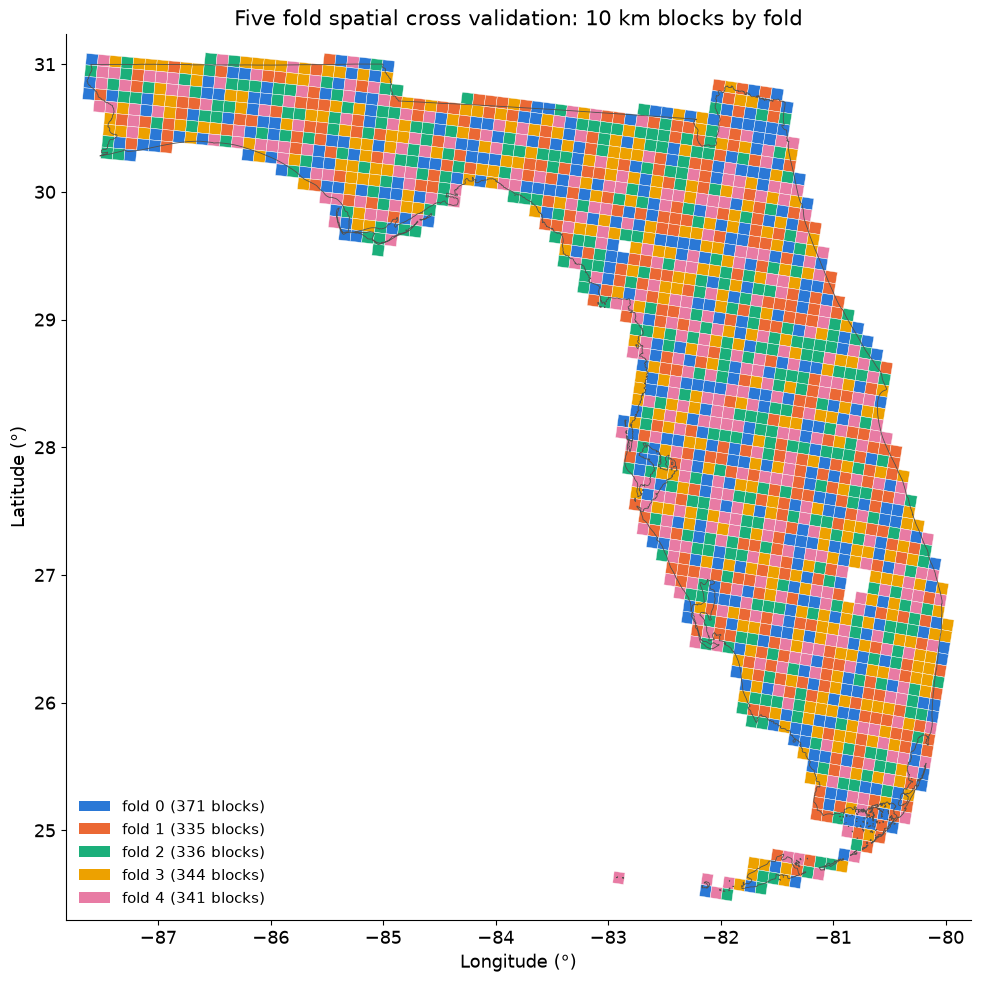

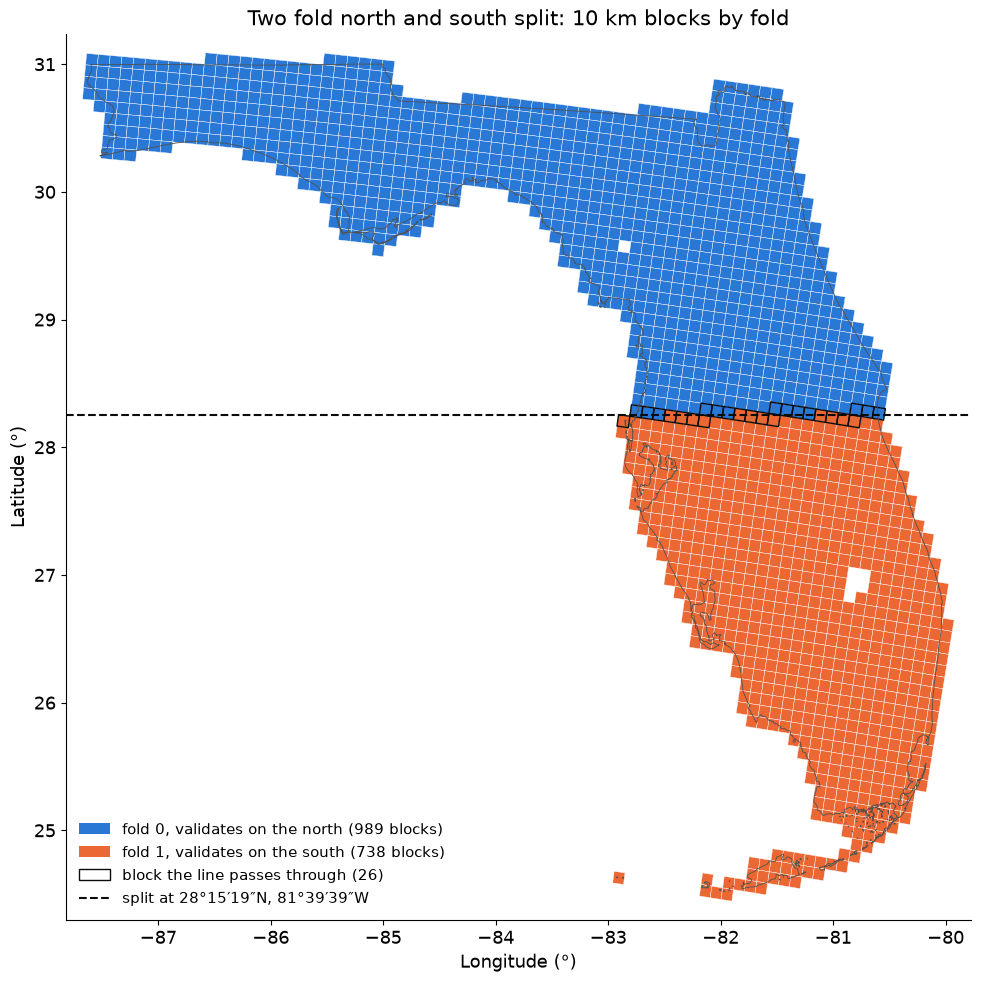

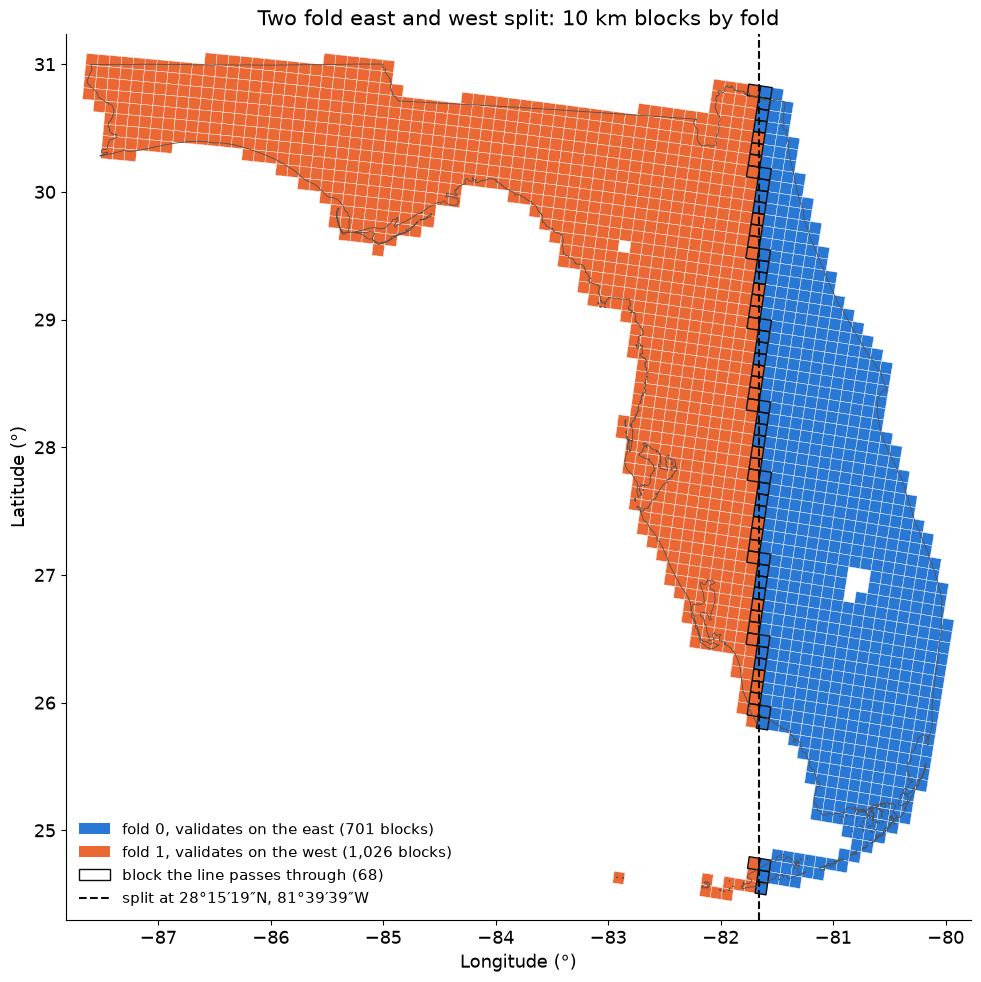

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

FIG_DIR = ROOT / "results/figures/fold_analysis"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Categorical slots 1 to 5 of the reference palette, in fixed order.
FOLD_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13,
                     "legend.fontsize": 11})

# Block squares in lon/lat. Corners go through pyproj one by one, so the squares
# come out slightly rotated, which is the Albers grid's real tilt against true north.
to_ll = Transformer.from_crs(5070, 4326, always_xy=True)
x0 = origin["u0"] + folds.BLOCK_M * bcol
y0 = origin["v0"] - folds.BLOCK_M * brow
corner_x = np.stack([x0, x0 + folds.BLOCK_M, x0 + folds.BLOCK_M, x0], axis=1)
corner_y = np.stack([y0, y0, y0 + folds.BLOCK_M, y0 + folds.BLOCK_M], axis=1)
corner_lon, corner_lat = to_ll.transform(corner_x, corner_y)
squares = np.stack([corner_lon, corner_lat], axis=2)

florida = gpd.read_file(ROOT / "data/boundaries/cb_2023_us_state_500k/cb_2023_us_state_500k.shp")
florida = florida.loc[florida["NAME"] == "Florida"].to_crs(4326)

pad = 0.15
lon_lim = (corner_lon.min() - pad, corner_lon.max() + pad)
lat_lim = (corner_lat.min() - pad, corner_lat.max() + pad)
center_lat, center_lon = folds.SPLIT_CENTER


def fold_map(code, names, title, out_name, scheme=None):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.add_collection(PolyCollection(
        squares, facecolors=[FOLD_COLORS[f] for f in code],
        edgecolors="#fcfcfb", linewidths=0.3,
    ))
    florida.boundary.plot(ax=ax, color=INK_2, linewidth=0.6)

    handles = [Patch(facecolor=FOLD_COLORS[i], label=f"{names[i]} ({int((code == i).sum()):,} blocks)")
               for i in range(len(names))]
    if scheme is not None:
        along = corner_lat if scheme == "north_south" else corner_lon
        at = center_lat if scheme == "north_south" else center_lon
        cut = (along.min(axis=1) < at) & (along.max(axis=1) > at)
        ax.add_collection(PolyCollection(squares[cut], facecolors="none",
                                         edgecolors=INK, linewidths=1.0))
        if scheme == "north_south":
            ax.plot(lon_lim, [at, at], color=INK, linewidth=1.5, linestyle="--")
        else:
            ax.plot([at, at], lat_lim, color=INK, linewidth=1.5, linestyle="--")
        handles += [
            Patch(facecolor="none", edgecolor=INK, linewidth=1.0,
                  label=f"block the line passes through ({int(cut.sum())})"),
            Line2D([], [], color=INK, linewidth=1.5, linestyle="--",
                   label=f"split at {folds.SPLIT_CENTER_DMS}"),
        ]

    ax.set_xlim(lon_lim)
    ax.set_ylim(lat_lim)
    # Degrees of longitude are shorter than degrees of latitude this far south.
    ax.set_aspect(1 / np.cos(np.radians(center_lat)))
    ax.set_xlabel("Longitude (°)")
    ax.set_ylabel("Latitude (°)")
    ax.set_title(title)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(handles=handles, loc="lower left", frameon=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / out_name, dpi=200)
    plt.show()


fold_map(blocked_code, [f"fold {i}" for i in range(hmt.BLOCKED_N_SPLITS)],
         "Five fold spatial cross validation: 10 km blocks by fold", "folds_blocked.png")
fold_map(geo_codes["north_south"], ["fold 0, validates on the north", "fold 1, validates on the south"],
         "Two fold north and south split: 10 km blocks by fold", "folds_north_south.png",
         scheme="north_south")
fold_map(geo_codes["east_west"], ["fold 0, validates on the east", "fold 1, validates on the west"],
         "Two fold east and west split: 10 km blocks by fold", "folds_east_west.png",
         scheme="east_west")

## Train and validation blocks, fold by fold, five fold blocked CV

One map per fold of the default `FOLD_SCHEME = "blocked"` split: that fold's validation blocks against the four folds it trains on. Under each map are the train and validation counts and rates for that fold. Train counts every cell, which matches the script since `MIN_WETLAND_TRAIN = 1`. Shares are of all cells and all wetland, and the stage two regressor trains and validates only on the `n_cells_any_conversion` cells.

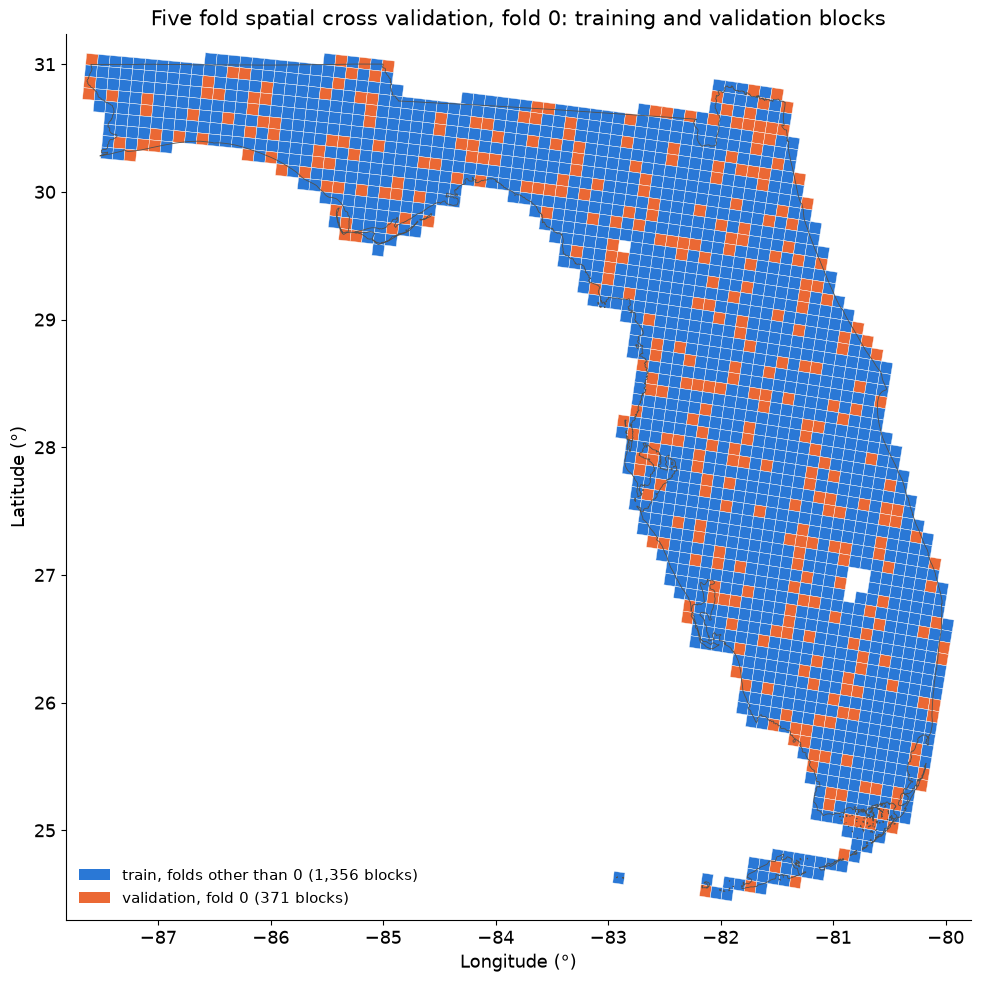

,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
train,"1,356","933,021","29,066","47,400,551","136,518",79.7%,80.0%,0.288%,3.12%
validation,371,"237,442","6,786","11,866,780","29,390",20.3%,20.0%,0.248%,2.86%


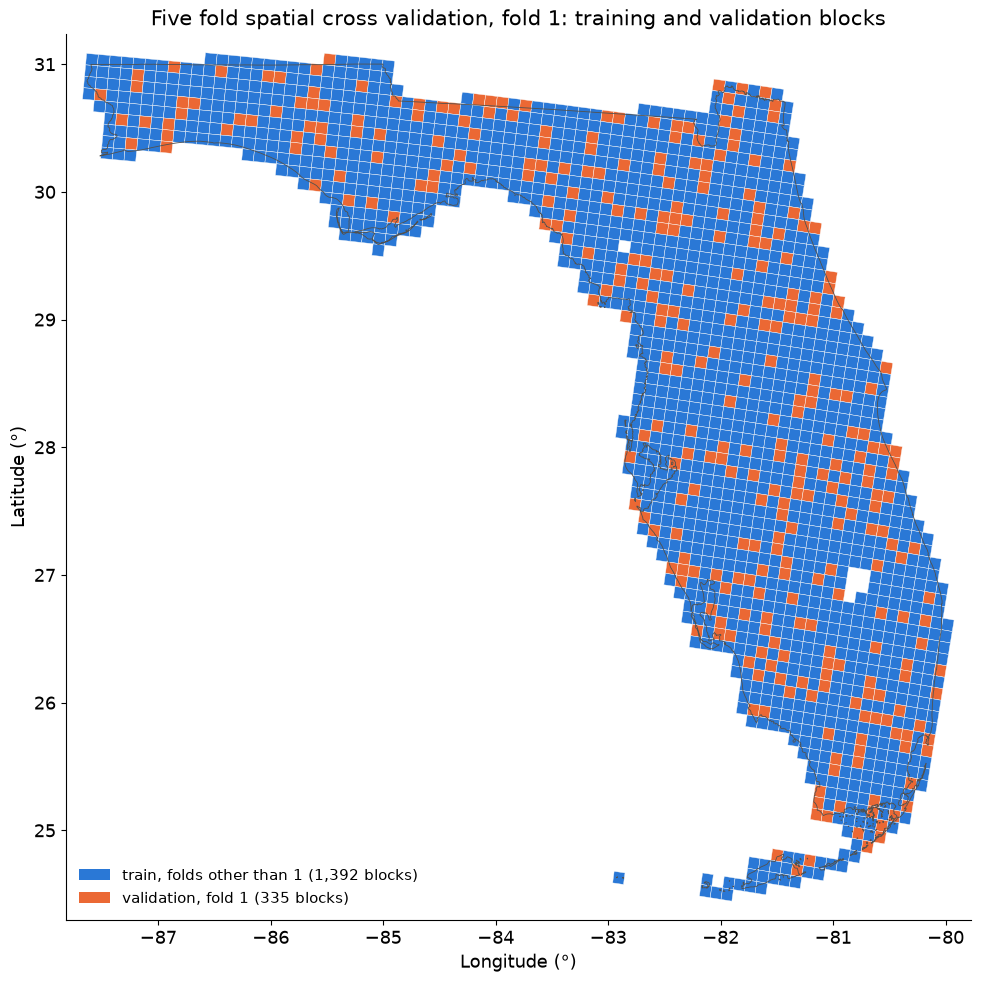

,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
train,"1,392","935,294","27,942","47,422,206","126,785",79.9%,80.0%,0.267%,2.99%
validation,335,"235,169","7,910","11,845,125","39,123",20.1%,20.0%,0.330%,3.36%


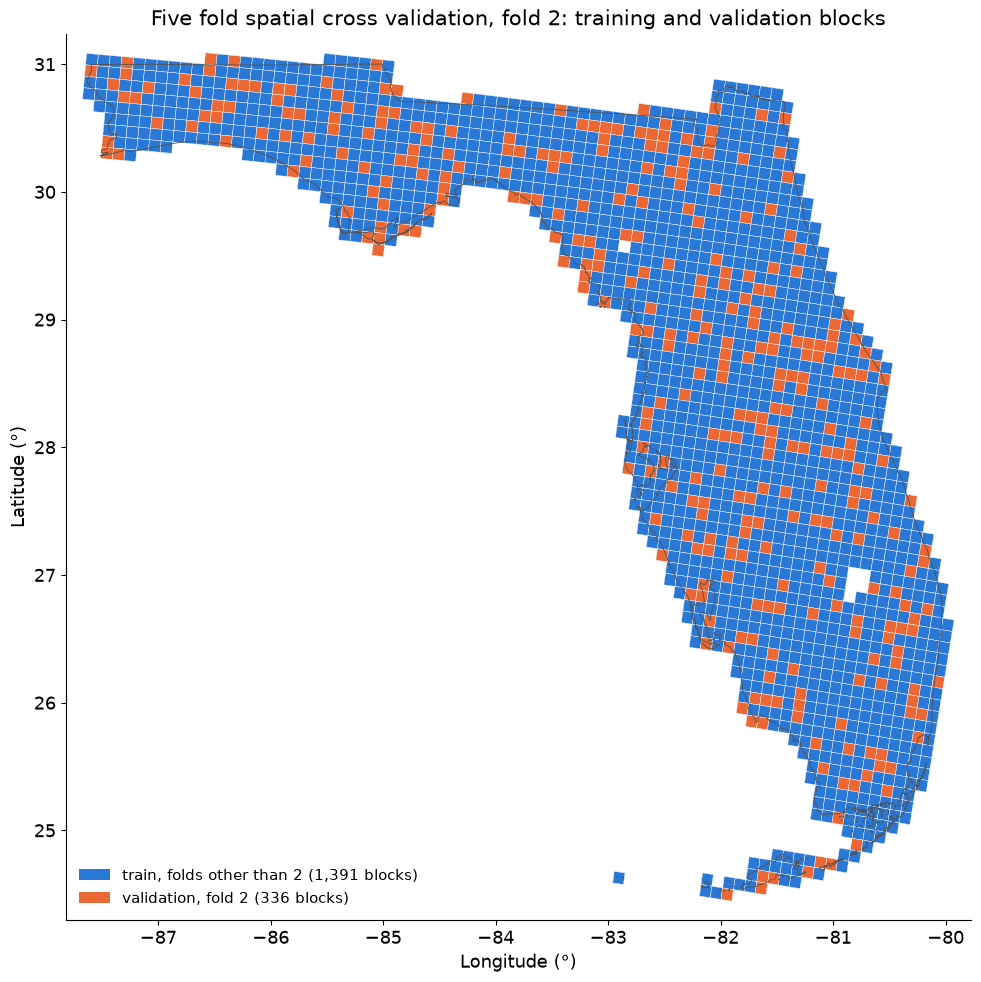

,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
train,"1,391","938,755","29,242","47,426,242","135,446",80.2%,80.0%,0.286%,3.11%
validation,336,"231,708","6,610","11,841,089","30,462",19.8%,20.0%,0.257%,2.85%


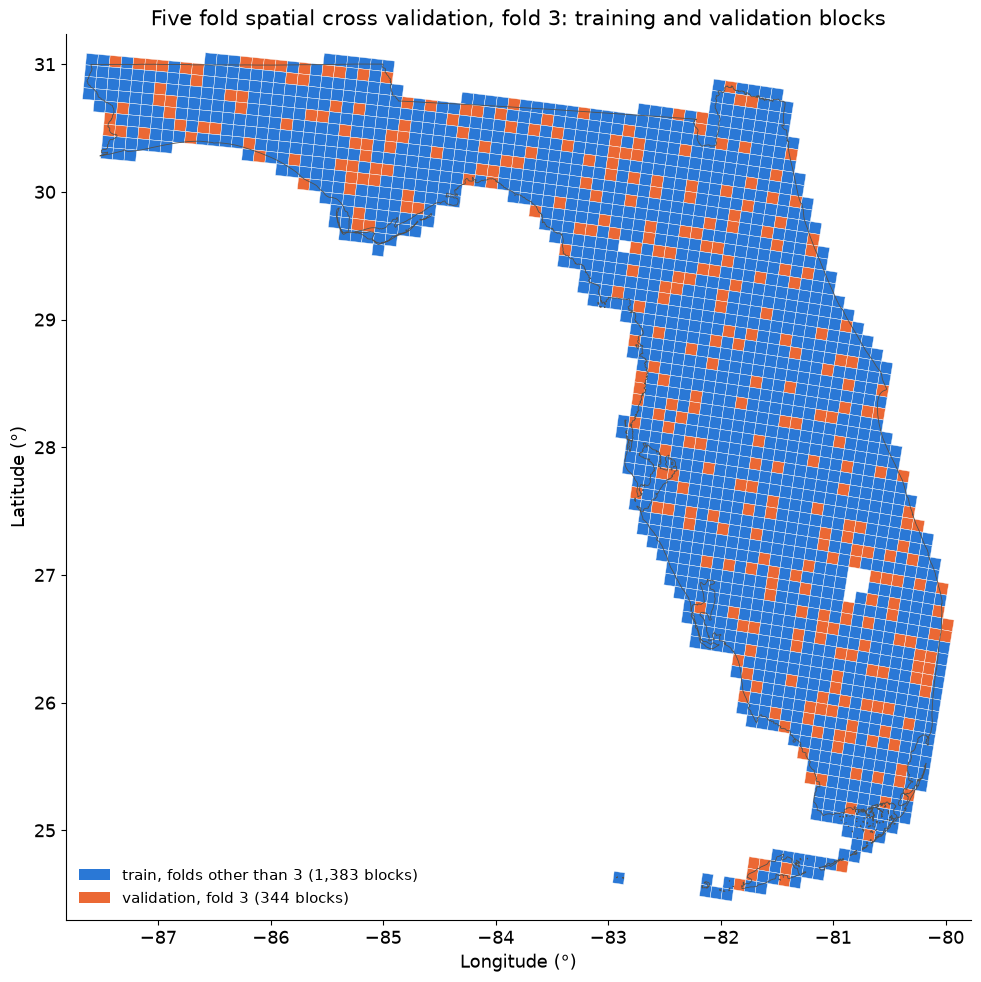

,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
train,"1,383","936,699","29,445","47,413,095","135,503",80.0%,80.0%,0.286%,3.14%
validation,344,"233,764","6,407","11,854,236","30,405",20.0%,20.0%,0.256%,2.74%


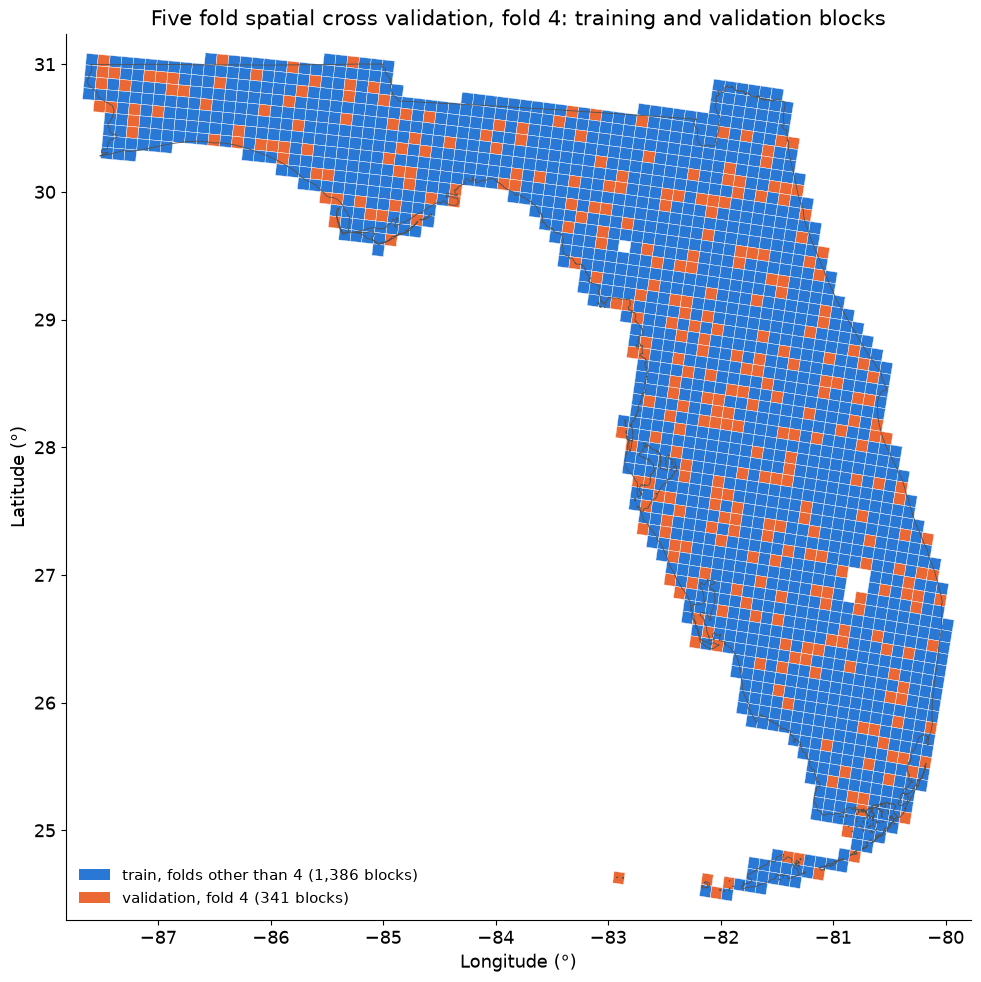

,n_blocks,n_cells,n_cells_any_conversion,wetland_px,developed_px,share_of_cells,share_of_wetland,pixel_conversion_rate,any_conversion_rate
train,"1,386","938,083","27,713","47,407,230","129,380",80.1%,80.0%,0.273%,2.95%
validation,341,"232,380","8,139","11,860,101","36,528",19.9%,20.0%,0.308%,3.50%


In [7]:
from IPython.display import display

ROLES = ["train", "validation"]
for k in range(hmt.BLOCKED_N_SPLITS):
    role = (blocked_code == k).astype(blocked_code.dtype)
    fold_map(role, [f"train, folds other than {k}", f"validation, fold {k}"],
             f"Five fold spatial cross validation, fold {k}: training and validation blocks",
             f"folds_blocked_fold_{k}.png")
    display(fold_summary(role, ROLES).drop(index="all").style.format(FMT))